# 🔋 Analisis Telemetri Degradasi Baterai EV & Ekstraksi Informasi Strategis

Notebook ini berisi analisis data telemetri komprehensif (*End-to-End Analytics*) untuk memecahkan **3 Masalah Kritis** dalam operasional dan investasi kendaraan listrik (EV):
1. **Masalah 1: Baterai rusak diam-diam, peringatannya terlambat** (Keterlambatan sinyal risiko & urgensi alarm hambatan dalam).
2. **Masalah 2: Salah memilih jenis baterai untuk pemakaian tertentu** (Ketidaksesuaian kimia baterai terhadap intensitas pemakaian dan iklim).
3. **Masalah 3: Pola pemakaian berat mempercepat kerusakan tanpa disadari** (Akselerasi degradasi akibat jarak jauh, *fast charge* sering, dan pengosongan dalam).

## 🎯 Ringkasan Informasi Strategis: Untuk Siapa, Masalah, dan Solusi

| # | Masalah | Untuk Siapa | Solusi Utama | Bukti Visual |
|---|---|---|---|---|
| **1** | Baterai rusak diam-diam, peringatannya terlambat | Tim Operasional Armada, Teknisi Perawatan, Produsen EV | Pasang alarm dini hambatan dalam 60–70 mΩ dan jadwalkan servis sebelum label Medium/High | Modul 5 — Visualisasi Masalah 1 |
| **2** | Salah memilih kimia sel untuk pola pemakaian dan iklim | Tim Pengadaan (*Procurement*), Pabrikan EV, Perusahaan Leasing & Asuransi | Wajibkan LFP untuk armada berat/tropis; batasi NMC/NCA untuk pemakaian ringan; hindari LMO untuk armada intensif | Modul 5 — Visualisasi Masalah 2 |
| **3** | Pola pemakaian berat mempercepat kerusakan tanpa disadari | *Fleet Manager*, Operator SPKLU/CPO, Pengembang Software BMS | Rotasi unit, batasi fast charge dan DoD via BMS, serta terapkan *smart charging* | Modul 5 — Visualisasi Masalah 3 |

> **Catatan bukti:** Seluruh angka pada visualisasi dan ringkasan dihitung langsung dari dataset di notebook ini (bukan angka asumsi). Dataset bersifat sintetis dan ditujukan untuk edukasi, benchmark metodologi, serta pengembangan analitik—bukan dasar keputusan finansial, keselamatan, atau garansi riil.

Setiap modul dan cell dilengkapi penjelasan fungsi teknis, logika domain elektrokimia baterai, visualisasi terfokus, serta rekomendasi aksi operasional.


---
## 📘 Tentang Dataset: Apa itu Dataset Ini?

Dataset ini adalah **EV Battery Health & Degradation Telemetry Dataset**, yaitu kumpulan data telemetri longitudinal yang merekam perilaku degradasi dan penuaan (*aging behavior*) dari paket baterai kendaraan listrik sepanjang masa pakainya.

### 1. Karakteristik & Skala Data:
- **Jumlah Observasi**: 50.000 rekaman telemetri berkala (*longitudinal observations*).
- **Entitas Fisik**: 2.600 paket baterai fisik unik (`battery_id`), masing-masing dipantau secara berulang (~10 hingga 40 pembacaan telemetri per unit) dari kondisi baru hingga mendekati akhir masa pakai.
- **Sifat Data**: Merupakan *physics-informed synthetic dataset* yang dimodelkan berdasarkan literatur ilmiah penuaan baterai (seperti riset NASA Prognostics Center of Excellence dan studi siklus hidup baterai elektrokimia).

### 2. Empat Kimia Sel yang Dianalisis:
1. **LFP (Lithium Iron Phosphate / LiFePO4)**: Dikenal sangat stabil, usia siklus sangat panjang, tahan terhadap termal ekstrem, namun densitas energi lebih rendah.
2. **NMC (Nickel Manganese Cobalt)**: Standar industri kendaraan listrik modern, menawarkan keseimbangan tinggi antara kapasitas energi, output daya, dan ketahanan siklus.
3. **NCA (Nickel Cobalt Aluminum)**: Menawarkan densitas energi tertinggi (jarak tempuh terjauh), namun lebih sensitif terhadap suhu panas dan degradasi pengisian cepat.
4. **LMO (Lithium Manganese Oxide)**: Menawarkan daya tinggi dan biaya terjangkau, namun memiliki laju kelarutan mangan yang mempercepat penurunan kapasitas seiring usia.

### 3. Masalah Nyata yang Dijawab:
Baterai merupakan komponen termahal dari kendaraan listrik (30% - 40% dari total nilai kendaraan). Dataset ini memungkinkan kita menemukan pola kegagalan dini, mengoptimalkan pemilihan jenis kimia sel sesuai kebutuhan beban, serta mengatur kebijakan penggunaan agar armada terhindar dari *downtime* mendadak.

---
## 🧭 Panduan Makna dan Struktur Tiap Cell

Notebook ini disusun secara runtut dalam 7 bagian:
- **Modul 0 (Setup)**: Mempersiapkan dependensi komputasi dan standarisasi visualisasi.
- **Modul 1 (Data Ingestion & Data Dictionary)**: Memuat dataset dan memeriksa makna 35 kolom fitur.
- **Modul 2 (Kualitas Data Mentah)**: Mengaudit missing values dan anomali telemetri.
- **Modul 3 (Data Cleaning Berbasis Domain)**: Membersihkan data menggunakan logika fisika deret waktu baterai (*group-wise longitudinal imputation*).
- **Modul 4 (Feature Engineering)**: Membentuk indikator hambatan dalam, kelompok jarak harian, dan faktor pemakaian berat.
- **Modul 5 (Visualisasi 3 Masalah Strategis)**: Rangkaian grafik multi-panel yang membuktikan Masalah 1, Masalah 2, dan Masalah 3, disertai blok **Untuk Siapa, Masalah, Solusi, dan Bukti Visual**.
- **Modul 6 (Penentuan Informasi Strategis)**: Sintesis temuan, dampak, solusi, dan pembagian target pengguna untuk masing-masing masalah dalam format tabel keputusan.


---
## Modul 0: Import Library & Setup Lingkungan Komputasi

> **Makna & Fungsi Cell Berikut**:
> Cell ini mengimpor seluruh pustaka Python yang dibutuhkan:
> - `pandas` & `numpy`: Manipulasi data tabular dan operasi numerik berkinerja tinggi.
> - `matplotlib.pyplot` & `seaborn`: Pustaka visualisasi grafik analitik berkualitas tinggi.
> - Mengatur tema visualisasi (`seaborn-v0_8-whitegrid`) dengan DPI 110 agar visualisasi terbaca jelas dan profesional.

In [1]:
# Import library esensial
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Konfigurasi tema dan resolusi grafik
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 110

print("Library dan konfigurasi visualisasi berhasil dimuat.")

Library dan konfigurasi visualisasi berhasil dimuat.


---
## Modul 1: Pemuatan Data & Kamus Data (Data Ingestion)

> **Makna & Fungsi Cell Berikut**:
> Cell ini memuat data mentah `ev_battery_health.csv` dan kamus data `data_dictionary .csv`.
> Menggunakan pengecekan path dinamis sehingga file notebook dapat dijalankan baik langsung dari dalam folder `notebook/` maupun dari folder root proyek.

In [2]:
# Path dataset (fleksibel: dijalankan dari root maupun folder notebook)
data_path = os.path.join('data', 'ev_battery_health.csv') if os.path.exists(os.path.join('data', 'ev_battery_health.csv')) else os.path.join('..', 'data', 'ev_battery_health.csv')
dict_path = os.path.join('data', 'data_dictionary .csv') if os.path.exists(os.path.join('data', 'data_dictionary .csv')) else os.path.join('..', 'data', 'data_dictionary .csv')

# Load data tabular
df_raw = pd.read_csv(data_path)
df_dict = pd.read_csv(dict_path)

print(f"Total baris data: {df_raw.shape[0]:,}")
print(f"Total fitur/kolom: {df_raw.shape[1]}")
print(f"Jumlah paket baterai unik (battery_id): {df_raw['battery_id'].nunique():,}")
print(f"Rata-rata observasi per unit baterai: {len(df_raw) / df_raw['battery_id'].nunique():.1f} observasi")

# Preview 5 baris pertama data mentah
df_raw.head()

Total baris data: 50,000
Total fitur/kolom: 35


Jumlah paket baterai unik (battery_id): 2,600
Rata-rata observasi per unit baterai: 19.2 observasi


,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


### Penjelasan Makna Setiap Kolom (Data Dictionary)

> **Makna & Fungsi Cell Berikut**:
> Menampilkan daftar lengkap seluruh 35 kolom telemetri yang dikelompokkan ke dalam 4 domain:
> 1. **Identitas & Spesifikasi Fisik**: `battery_id`, `observation_id`, `chemistry`, `manufacturer`, `vehicle_model`, `pack_capacity_kwh`, `manufacture_date`.
> 2. **Metrik Operasional & Pengisian Daya**: `battery_age_days`, `cycle_count`, `avg_daily_distance_km`, `avg_charging_power_kw`, `fast_charge_ratio`, `avg_depth_of_discharge_pct`, `avg_state_of_charge_pct`, `charge_cycles_per_month`, `total_energy_throughput_kwh`, `charge_time_avg_min`.
> 3. **Sensor Lingkungan & Kondisi Listrik**: `climate_zone`, `avg_ambient_temp_c`, `humidity_pct`, `altitude_m`, `internal_resistance_mohm`, `voltage_avg_v`, `current_avg_a`, `peak_temp_during_fast_charge_c`, `bms_firmware_version`, `service_count`, `last_service_date`, `recall_flag`.
> 4. **Variabel Target Evaluasi**:
>    - `state_of_health_pct` (SOH): Persentase kapasitas tersisa terhadap kondisi baru (%).
>    - `remaining_useful_life_cycles` (RUL): Sisa siklus pengisian sebelum SOH jatuh ke batas pensiun 80%.
>    - `failure_risk_label`: Status risiko kegagalan (*Low, Medium, High*).
>    - `degradation_category`: Pola laju degradasi (*Normal, Accelerated, Critical*).

In [3]:
# Menampilkan kamus data secara rapi
pd.set_option('display.max_rows', 40)
pd.set_option('display.max_colwidth', None)
df_dict[['column', 'dtype', 'unit', 'description']]

,column,dtype,unit,description
0,battery_id,string,-,"Unique identifier for a physical battery pack (2,600 unique batteries)"
1,observation_id,string,-,Unique identifier for a single longitudinal observation/reading
2,chemistry,categorical,-,"Cell chemistry: LFP, NMC, NCA, or LMO"
3,manufacturer,categorical,-,Battery pack manufacturer (synthetic brand names)
4,vehicle_model,categorical,-,EV model/platform the pack is installed in
5,pack_capacity_kwh,float,kWh,Nominal (rated new) pack energy capacity
6,manufacture_date,date,YYYY-MM-DD,Date the battery pack was manufactured
7,observation_date,date,YYYY-MM-DD,Date of this telemetry/health observation
8,battery_age_days,int,days,Days elapsed since manufacture at time of observation
9,cycle_count,int,cycles,Cumulative equivalent full charge cycles at time of observation


---
## Modul 2: Diagnosis Kualitas Data Mentah (Missing Values)

> **Makna & Fungsi Cell Berikut**:
> Cell ini mengaudit integritas data sebelum proses pembersihan:
> - Memeriksa persentase missing values pada setiap kolom.
> - Mengonfirmasi apakah terdapat kolom dengan *structural missingness* (seperti `last_service_date` yang kosong saat `service_count == 0`) serta *injected missingness* pada sinyal sensorik (~3-8%).

In [4]:
# Audit kolom yang memiliki missing values
missing_df = pd.DataFrame({
    'Tipe Data': df_raw.dtypes,
    'Jumlah Missing': df_raw.isnull().sum(),
    'Persentase Missing (%)': (df_raw.isnull().sum() / len(df_raw) * 100).round(2)
})
missing_df = missing_df[missing_df['Jumlah Missing'] > 0].sort_values(by='Jumlah Missing', ascending=False)
print("Ringkasan Kolom dengan Nilai Hilang (Missing Values):")
missing_df

Ringkasan Kolom dengan Nilai Hilang (Missing Values):


,Tipe Data,Jumlah Missing,Persentase Missing (%)
last_service_date,object,18831,37.66
vehicle_model,object,3515,7.03
chemistry,object,3459,6.92
fast_charge_ratio,float64,3405,6.81
total_energy_throughput_kwh,float64,3370,6.74
avg_ambient_temp_c,float64,3282,6.56
avg_state_of_charge_pct,float64,3138,6.28
battery_age_days,float64,3002,6.00
avg_depth_of_discharge_pct,float64,2832,5.66
voltage_avg_v,float64,2807,5.61


---
## Modul 3: Pembersihan Data (Data Cleaning Berbasis Domain Fisika Baterai)

> **Makna & Fungsi Cell Berikut**:
> Cell ini mengeksekusi pembersihan data berbasis prinsip fisika dan deret waktu:
> 1. **Pemanfaatan Sifat Longitudinal (Group Imputation)**: Atribut paket baterai yang bersifat konstan (`chemistry`, `manufacturer`, `vehicle_model`, `pack_capacity_kwh`, `climate_zone`, dll.) diisi secara maju/mundur (`ffill().bfill()`) yang dikelompokkan per `battery_id`.
> 2. **Rekonstruksi Usia & Tanggal Observasi**: `battery_age_days` yang hilang dihitung dari `observation_date - manufacture_date`; sisa baris yang tanggal dan usianya sama-sama hilang diestimasi dari `cycle_count` memakai rasio median hari/siklus per baterai. Setelah itu, `observation_date` yang hilang direkonstruksi dari $\text{manufacture\_date} + \text{battery\_age\_days}$.
> 3. **Interpolasi Sensorik Dinamis**: Sensor operasi kontinu diimputasi menggunakan interpolasi linier deret waktu per unit baterai.
> 4. **Penanganan Struktural Servis**: Mengkategorikan kolom status servis baterai.
> 5. **Pembersihan Outlier Sensorik**: Membatasi nilai anomali ekstrem akibat gangguan telemetri (suhu ambient > 55°C, suhu pengisian > 70°C, durasi charging > 360 menit) pada ambang batas operasional fisik EV.

In [5]:
df = df_raw.copy()

# 1. Konversi format datetime
df['manufacture_date'] = pd.to_datetime(df['manufacture_date'])
df['observation_date'] = pd.to_datetime(df['observation_date'])

# Urutkan berdasarkan unit baterai dan usia untuk menjaga urutan longitudinal yang runtut
df = df.sort_values(by=['battery_id', 'battery_age_days']).reset_index(drop=True)

# 2. Imputasi Atribut Statis per Paket Baterai (battery_id)
static_cols = [
    'chemistry', 'manufacturer', 'vehicle_model', 'pack_capacity_kwh',
    'manufacture_date', 'bms_firmware_version', 'recall_flag', 'climate_zone'
]
for col in static_cols:
    df[col] = df.groupby('battery_id')[col].transform(lambda s: s.ffill().bfill())

# 3. Rekonstruksi battery_age_days dari tanggal, lalu estimasi sisanya dari cycle_count
#    Usia tidak diinterpolasi dengan urutan yang menaruh NaN di akhir, karena pola itu
#    membuat baris berusia hilang terisi usia maksimum dan merusak snapshot armada.
age_from_date = (df['observation_date'] - df['manufacture_date']).dt.days
df['battery_age_days'] = df['battery_age_days'].fillna(age_from_date)

# Untuk baris yang tanggal dan usianya sama-sama hilang, estimasi usia dari cycle_count
# memakai rasio median hari/siklus per baterai (fallback: rasio global).
cycle_ratio = (df['battery_age_days'] / df['cycle_count']).replace([np.inf, -np.inf], np.nan)
ratio_per_battery = cycle_ratio.groupby(df['battery_id']).median()
global_ratio = cycle_ratio.median()
missing_age = df['battery_age_days'].isna()
estimated_age = (
    df.loc[missing_age, 'cycle_count']
    * df.loc[missing_age, 'battery_id'].map(ratio_per_battery).fillna(global_ratio)
)
df.loc[missing_age, 'battery_age_days'] = estimated_age
df['battery_age_days'] = df['battery_age_days'].fillna(
    df.groupby('battery_id')['battery_age_days'].transform('median')
)
df['battery_age_days'] = df['battery_age_days'].fillna(df['battery_age_days'].median())

# Rekonstruksi observation_date yang hilang setelah usia valid
missing_obs = df['observation_date'].isnull()
df.loc[missing_obs, 'observation_date'] = (
    df.loc[missing_obs, 'manufacture_date'] +
    pd.to_timedelta(df.loc[missing_obs, 'battery_age_days'], unit='D')
)

# Urutkan ulang setelah koreksi usia agar interpolasi sensor tetap longitudinal
df = df.sort_values(['battery_id', 'battery_age_days']).reset_index(drop=True)

# 4. Imputasi Nilai Sensor Dinamis via Interpolasi Linear Longitudinal
dynamic_cols = [
    'cycle_count', 'avg_daily_distance_km', 'avg_charging_power_kw',
    'fast_charge_ratio', 'avg_depth_of_discharge_pct', 'avg_state_of_charge_pct',
    'charge_cycles_per_month', 'total_energy_throughput_kwh', 'avg_ambient_temp_c',
    'humidity_pct', 'altitude_m', 'internal_resistance_mohm', 'voltage_avg_v',
    'current_avg_a', 'charge_time_avg_min', 'peak_temp_during_fast_charge_c',
    'capacity_fade_pct', 'service_count'
]
for col in dynamic_cols:
    df[col] = df.groupby('battery_id')[col].transform(
        lambda s: s.interpolate(method='linear').ffill().bfill()
    )

# 5. Penanganan Kolom last_service_date (Struktural)
df['last_service_date'] = pd.to_datetime(df['last_service_date'])
df['service_status'] = np.where(df['service_count'] > 0, 'Pernah Servis', 'Belum Pernah Servis')

# 6. Pembersihan Outlier Sensorik Menggunakan Batas Fisik EV
df['avg_ambient_temp_c'] = df['avg_ambient_temp_c'].clip(lower=-30.0, upper=55.0)
df['peak_temp_during_fast_charge_c'] = df['peak_temp_during_fast_charge_c'].clip(lower=-20.0, upper=70.0)
df['charge_time_avg_min'] = df['charge_time_avg_min'].clip(lower=10.0, upper=360.0)

# Verifikasi kebersihan data (di luar last_service_date struktural)
sisa_null = df.drop(columns=['last_service_date']).isnull().sum().sum()
print(f"Data Cleaning Berhasil! Sisa missing values (selain last_service_date struktural): {sisa_null}")
df.info()

Data Cleaning Berhasil! Sisa missing values (selain last_service_date struktural): 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 36 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   battery_id                      50000 non-null  object        
 1   observation_id                  50000 non-null  object        
 2   chemistry                       50000 non-null  object        
 3   manufacturer                    50000 non-null  object        
 4   vehicle_model                   50000 non-null  object        
 5   pack_capacity_kwh               50000 non-null  float64       
 6   manufacture_date                50000 non-null  datetime64[ns]
 7   observation_date                50000 non-null  datetime64[ns]
 8   battery_age_days                50000 non-null  float64       
 9   cycle_count                     50000 non-null  float

---
## Modul 4: Pra-Processing & Feature Engineering

> **Makna & Fungsi Cell Berikut**:
> Cell ini merekayasa fitur-fitur analitik khusus untuk membedah ketiga masalah strategis:
> 1. **`res_bracket`**: Interval hambatan dalam baterai (`<60 mΩ`, `60-70 mΩ`, `70-80 mΩ`, `80-90 mΩ`, `>90 mΩ`) untuk menguji sinyal alarm dini (*Masalah 1*).
> 2. **`distance_bracket`**: Segmentasi jarak pemakaian harian (`< 30 km`, `30 - 60 km`, `60 - 100 km`, `> 100 km/hari`) untuk mengukur intensitas pemakaian (*Masalah 2 & 3*).
> 3. **`heavy_use_combo`**: Indikator gabungan pemakaian berat (Jarak tempuh >100 km + Fast charge sering >50% + Pengosongan dalam DOD >70%) (*Masalah 3*).
> 4. **`is_retired`**: Indikator apakah baterai telah melewati batas pensiun otomotif ($\text{SOH} \le 80\%$).
> 5. **`df_latest`**: Snapshot observasi terakhir dari masing-masing 2.600 unit baterai untuk menilai kondisi riil armada saat ini.


In [6]:
# 1. Fitur Rentang Hambatan Dalam (Internal Resistance Bracket) untuk Alarm Dini
res_bins = [0, 60, 70, 80, 90, np.inf]
res_labels = ['< 60 mΩ', '60–70 mΩ', '70–80 mΩ', '80–90 mΩ', '> 90 mΩ']
df['res_bracket'] = pd.cut(df['internal_resistance_mohm'], bins=res_bins, labels=res_labels)

# 2. Fitur Segmentasi Jarak Tempuh Harian
dist_bins = [-np.inf, 30, 60, 100, np.inf]
dist_labels = ['< 30 km/hari', '30–60 km/hari', '60–100 km/hari', '> 100 km/hari']
df['distance_bracket'] = pd.cut(df['avg_daily_distance_km'], bins=dist_bins, labels=dist_labels)

# 3. Fitur Gabungan Pemakaian Berat (Multi-factor Stress)
df['heavy_use_combo'] = (
    (df['avg_daily_distance_km'] > 100).astype(int) + 
    (df['fast_charge_ratio'] > 0.50).astype(int) + 
    (df['avg_depth_of_discharge_pct'] > 70.0).astype(int)
)
combo_labels = {0: 'Beban Ringan (0 Faktor)', 1: '1 Faktor Berat', 2: '2 Faktor Berat', 3: 'Kombinasi Ekstrem (3 Faktor)'}
df['heavy_use_label'] = df['heavy_use_combo'].map(combo_labels)

# 4. Fitur Kelompok Siklus & Level Fast Charge
df['cycle_bracket'] = pd.cut(
    df['cycle_count'],
    bins=[-np.inf, 1000, 2000, 3000, np.inf],
    labels=['< 1.000 Siklus', '1.000–2.000 Siklus', '2.000–3.000 Siklus', '> 3.000 Siklus']
)
df['fast_charge_level'] = pd.cut(
    df['fast_charge_ratio'],
    bins=[-np.inf, 0.25, 0.50, 1.0],
    labels=['Rendah (<25%)', 'Sedang (25-50%)', 'Tinggi (>50%)']
)

# 5. Status Pensiun EV (SOH <= 80%)
df['is_retired'] = df['state_of_health_pct'] <= 80.0
df['is_high_risk'] = df['failure_risk_label'] == 'High'

# 6. Snapshot Observasi Terakhir Armada (2.600 Unit Baterai)
df_latest = df.sort_values('observation_date').groupby('battery_id').last().reset_index()

# Verifikasi angka agregasi
ever_retired_pct = (df.groupby('battery_id')['state_of_health_pct'].min() <= 80.0).mean() * 100
latest_high_pct = (df_latest['failure_risk_label'] == 'High').mean() * 100
latest_med_pct = (df_latest['failure_risk_label'] == 'Medium').mean() * 100

print(f"Proporsi baterai pernah menyentuh batas pensiun (<=80% SOH): {ever_retired_pct:.1f}%")
print(f"Status pada pengecekan terakhir armada: High = {latest_high_pct:.1f}%, Medium = {latest_med_pct:.1f}%")

Proporsi baterai pernah menyentuh batas pensiun (<=80% SOH): 22.1%
Status pada pengecekan terakhir armada: High = 18.5%, Medium = 17.6%


---
## Modul 5: Visualisasi untuk Informasi Strategis

Bagian ini menyajikan **3 set visualisasi analitik terfokus**. Setiap set diawali dengan blok **🎯 Untuk Siapa**, **❗ Masalah**, **✅ Solusi**, dan **📊 Bukti Visual**, lalu dilanjutkan dengan grafik yang dihitung langsung dari dataset:
- **Visualisasi Masalah 1**: Keterlambatan sinyal risiko vs efektivitas hambatan dalam sebagai alarm dini (untuk Tim Operasional Armada, Teknisi Perawatan, Produsen EV).
- **Visualisasi Masalah 2**: Disparitas daya tahan kimia sel terhadap jarak tempuh tinggi (>100 km/hari) dan sensitivitas iklim (untuk Tim Pengadaan, Pabrikan EV, Leasing & Asuransi).
- **Visualisasi Masalah 3**: Eskalasi laju kerusakan akibat jarak tempuh jauh dan pelipatgandaan risiko beban kombinasi (untuk Fleet Manager, Operator SPKLU/CPO, Pengembang BMS).

> **Prinsip penyajian:** angka pada grafik, narasi, dan tabel bukti berasal dari variabel yang sama (`rul_med`, `res_rate`, `retire_med`, `heavy_rate`, `nca_clim`, `dist_rate`, `combo_rate`) agar tidak terjadi selisih antara cerita dan data.


In [7]:
# ============================================================
# TABEL BUKTI KUANTITATIF: SEMUA ANGKA DIHITUNG DARI DATASET
# ============================================================
chem_order = ['LFP', 'NMC', 'NCA', 'LMO']

# Masalah 1: keterlambatan label risiko dan alarm hambatan dalam
rul_med = (
    df.groupby('failure_risk_label')['remaining_useful_life_cycles']
      .median()
      .reindex(['Low', 'Medium', 'High'])
)
res_rate = (
    df.groupby('res_bracket', observed=False)['is_high_risk'].mean() * 100
).reindex(['< 60 mΩ', '60–70 mΩ', '70–80 mΩ', '80–90 mΩ', '> 90 mΩ'])
latest_high_pct = (df_latest['failure_risk_label'] == 'High').mean() * 100
latest_med_pct = (df_latest['failure_risk_label'] == 'Medium').mean() * 100
ever_retired_pct = (
    df.groupby('battery_id')['state_of_health_pct'].min() <= 80
).mean() * 100

# Masalah 2: daya tahan kimia, beban rute berat, dan sensitivitas iklim
retired_obs = df[df['state_of_health_pct'] <= 80].sort_values(['battery_id', 'cycle_count'])
retire_first = retired_obs.groupby('battery_id').agg(
    chemistry=('chemistry', 'first'),
    cycle_count=('cycle_count', 'first')
)
retire_med = retire_first.groupby('chemistry')['cycle_count'].median().reindex(chem_order)
retire_n = retire_first.groupby('chemistry').size().reindex(chem_order).fillna(0).astype(int)
chem_n = df.groupby('chemistry')['battery_id'].nunique().reindex(chem_order)

heavy_df = df[df['avg_daily_distance_km'] > 100]
heavy_rate = (
    heavy_df.groupby('chemistry')['is_high_risk'].mean() * 100
).reindex(chem_order)

nca_df = df[
    (df['chemistry'] == 'NCA') &
    (df['climate_zone'].isin(['temperate', 'tropical_humid']))
]
nca_clim = (
    nca_df.groupby('climate_zone')['is_high_risk'].mean() * 100
).reindex(['temperate', 'tropical_humid'])
nca_delta = (nca_clim['tropical_humid'] / nca_clim['temperate'] - 1) * 100

# Masalah 3: jarak tempuh, kombinasi beban, dan fast charging
dist_rate = (
    df.groupby('distance_bracket', observed=False)['is_high_risk'].mean() * 100
).reindex(['< 30 km/hari', '30–60 km/hari', '60–100 km/hari', '> 100 km/hari'])
combo_rate = (
    df.groupby('heavy_use_combo')['is_high_risk'].mean() * 100
).reindex([0, 1, 2, 3])

bukti = pd.DataFrame([
    {
        'Masalah': '1. Peringatan risiko terlambat',
        'Metrik Bukti': 'Median RUL label Medium / High',
        'Nilai': f"{rul_med['Medium']:.0f} / {rul_med['High']:.0f} siklus",
    },
    {
        'Masalah': '1. Peringatan risiko terlambat',
        'Metrik Bukti': 'Risiko High saat hambatan dalam 60–70 mΩ / >90 mΩ',
        'Nilai': f"{res_rate.iloc[1]:.2f}% / {res_rate.iloc[-1]:.2f}%",
    },
    {
        'Masalah': '1. Kondisi armada terkini',
        'Metrik Bukti': 'High / Medium / pernah menyentuh 80% SOH',
        'Nilai': f"{latest_high_pct:.0f}% / {latest_med_pct:.0f}% / {ever_retired_pct:.0f}%",
    },
    {
        'Masalah': '2. Salah pilih kimia sel',
        'Metrik Bukti': 'Median siklus pertama menyentuh 80% SOH (LFP/NMC/NCA/LMO)',
        'Nilai': ' / '.join(f"{retire_med[c]:,.0f}" for c in chem_order),
    },
    {
        'Masalah': '2. Beban rute >100 km/hari',
        'Metrik Bukti': 'Risiko High per kimia (LFP/NMC/NCA/LMO)',
        'Nilai': ' / '.join(f"{heavy_rate[c]:.1f}%" for c in chem_order),
    },
    {
        'Masalah': '2. Sensitivitas iklim NCA',
        'Metrik Bukti': 'Risiko High iklim sedang vs tropis lembap',
        'Nilai': f"{nca_clim['temperate']:.1f}% vs {nca_clim['tropical_humid']:.1f}% (+{nca_delta:.0f}%)",
    },
    {
        'Masalah': '3. Pola pemakaian berat',
        'Metrik Bukti': 'Risiko High jarak <30 km/hari vs >100 km/hari',
        'Nilai': f"{dist_rate.iloc[0]:.1f}% vs {dist_rate.iloc[-1]:.1f}%",
    },
    {
        'Masalah': '3. Kombinasi beban berat',
        'Metrik Bukti': 'Risiko High pada 0 vs 3 faktor berat',
        'Nilai': f"{combo_rate.loc[0]:.1f}% vs {combo_rate.loc[3]:.1f}%",
    },
])

print("Seluruh angka pada tabel ini dihitung langsung dari dataset:")
display(bukti)

Seluruh angka pada tabel ini dihitung langsung dari dataset:

,Masalah,Metrik Bukti,Nilai
0,1. Peringatan risiko terlambat,Median RUL label Medium / High,53 / 0 siklus
1,1. Peringatan risiko terlambat,Risiko High saat hambatan dalam 60–70 mΩ / >90 mΩ,0.34% / 83.20%
2,1. Kondisi armada terkini,High / Medium / pernah menyentuh 80% SOH,18% / 18% / 22%
3,2. Salah pilih kimia sel,Median siklus pertama menyentuh 80% SOH (LFP/NMC/NCA/LMO),"3,216 / 1,723 / 1,576 / 1,165"
4,2. Beban rute >100 km/hari,Risiko High per kimia (LFP/NMC/NCA/LMO),0.3% / 12.9% / 16.2% / 26.9%
5,2. Sensitivitas iklim NCA,Risiko High iklim sedang vs tropis lembap,4.2% vs 10.5% (+148%)
6,3. Pola pemakaian berat,Risiko High jarak <30 km/hari vs >100 km/hari,3.1% vs 12.1%
7,3. Kombinasi beban berat,Risiko High pada 0 vs 3 faktor berat,4.5% vs 13.3%


### Visualisasi Masalah 1: Baterai Rusak Diam-diam, Peringatannya Terlambat

> **🎯 Untuk Siapa**: Tim Operasional Armada (taksi online, logistik, rental), Teknisi Perawatan (*Maintenance*), dan Produsen EV.
>
> **❗ Masalah**: Label risiko konvensional baru berubah ketika baterai hampir habis masa pakainya. Akibatnya servis dan penggantian baterai menjadi tindakan darurat, bukan terjadwal.
>
> **✅ Solusi**: Pantau hambatan dalam (*internal resistance*) melalui telemetri BMS. Jadwalkan pemeriksaan servis saat nilainya masuk **60–70 mΩ**, sebelum status risiko berubah Medium/High.
>
> **📊 Bukti Visual (dihitung dari dataset)**:
> - **Subplot A**: median sisa siklus (RUL) baterai berlabel **Medium hanya ~53 siklus** (sekitar 1–2 bulan operasional), sedangkan **High sudah 0 siklus**. Peringatan berbasis label konvensional datang terlalu terlambat.
> - **Subplot B**: tingkat risiko High naik bertahap dari **0,04%** (<60 mΩ), **0,34%** (60–70 mΩ), **5,42%** (70–80 mΩ), **28,71%** (80–90 mΩ), hingga **83,20%** (>90 mΩ).
> - **Subplot C**: pada pengecekan terakhir, **18,5%** baterai berstatus High dan **17,6%** Medium; secara keseluruhan **22%** unit pernah menyentuh batas pensiun 80% SOH.


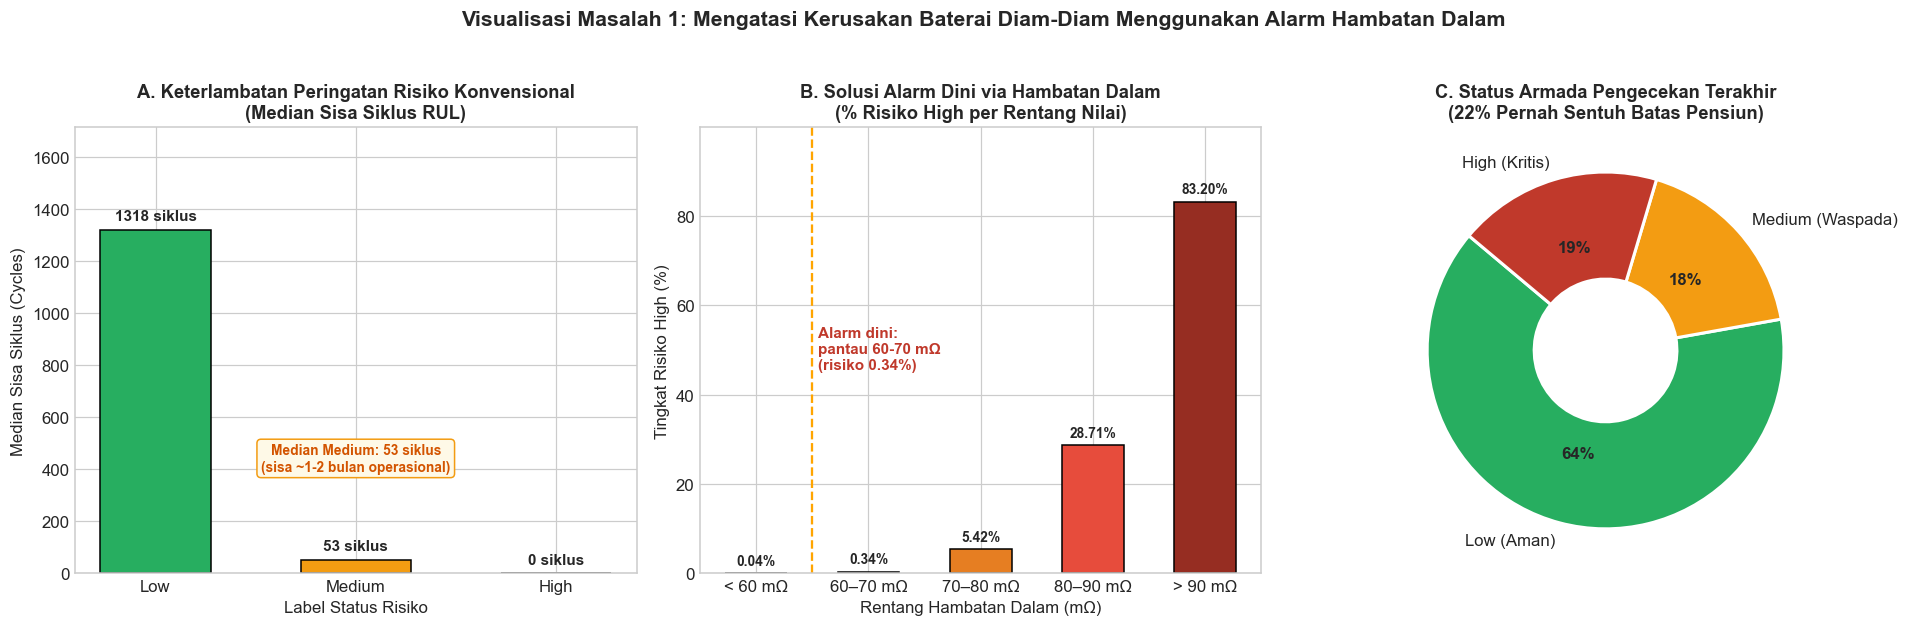

In [8]:
# Visualisasi Masalah 1: Bukti Kerusakan Diam-diam & Solusi Hambatan Dalam
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 1A: Median Sisa Siklus Pakai (RUL) Berdasarkan Label Risiko
rul_summary = rul_med.reindex(['Low', 'Medium', 'High'])
bars1 = axes[0].bar(
    rul_summary.index, rul_summary.values,
    color=['#27ae60', '#f39c12', '#c0392b'],
    edgecolor='black', width=0.55
)
axes[0].set_title('A. Keterlambatan Peringatan Risiko Konvensional\n(Median Sisa Siklus RUL)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Label Status Risiko', fontsize=11)
axes[0].set_ylabel('Median Sisa Siklus (Cycles)', fontsize=11)
axes[0].set_ylim(0, max(rul_summary.max() * 1.30, 100))
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + rul_summary.max() * 0.02,
        f"{yval:.0f} siklus",
        ha='center', va='bottom', fontweight='bold', fontsize=10
    )
axes[0].text(
    1, rul_summary.max() * 0.30,
    f"Median Medium: {rul_med['Medium']:.0f} siklus\n(sisa ~1-2 bulan operasional)",
    ha='center', color='#d35400', fontweight='bold', fontsize=9,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='#fef9e7', edgecolor='#f39c12')
)

# Subplot 1B: Tingkat Risiko High per Interval Hambatan Dalam
res_names = res_rate.index.tolist()
res_values = res_rate.values
bars2 = axes[1].bar(
    res_names, res_values,
    color=['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c', '#962d22'],
    edgecolor='black', width=0.55
)
axes[1].set_title('B. Solusi Alarm Dini via Hambatan Dalam\n(% Risiko High per Rentang Nilai)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Rentang Hambatan Dalam (mΩ)', fontsize=11)
axes[1].set_ylabel('Tingkat Risiko High (%)', fontsize=11)
axes[1].set_ylim(0, max(res_values) * 1.20)
axes[1].axvline(0.5, color='orange', linestyle='--', linewidth=1.5)
axes[1].text(
    0.55, max(res_values) * 0.55,
    f"Alarm dini:\npantau 60-70 mΩ\n(risiko {res_rate.iloc[1]:.2f}%)",
    color='#c0392b', fontweight='bold', fontsize=10
)
for bar, value in zip(bars2, res_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        value + max(res_values) * 0.015,
        f"{value:.2f}%",
        ha='center', va='bottom', fontweight='bold', fontsize=9
    )

# Subplot 1C: Snapshot Status Armada Terakhir
latest_risk_counts = df_latest['failure_risk_label'].value_counts()[['Low', 'Medium', 'High']]
wedges, texts, autotexts = axes[2].pie(
    latest_risk_counts,
    labels=['Low (Aman)', 'Medium (Waspada)', 'High (Kritis)'],
    autopct='%1.0f%%',
    startangle=140,
    colors=['#27ae60', '#f39c12', '#c0392b'],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2, 'width': 0.6}
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_weight('bold')
axes[2].set_title(f'C. Status Armada Pengecekan Terakhir\n({ever_retired_pct:.0f}% Pernah Sentuh Batas Pensiun)', fontsize=12, fontweight='bold')

plt.suptitle('Visualisasi Masalah 1: Mengatasi Kerusakan Baterai Diam-Diam Menggunakan Alarm Hambatan Dalam', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Visualisasi Masalah 2: Salah Memilih Jenis Baterai untuk Pemakaian Tertentu

> **🎯 Untuk Siapa**: Tim Pengadaan (*Procurement*), Pabrikan EV (R&D dan pemilihan chemistry), serta Perusahaan Leasing & Asuransi (proyeksi nilai sisa dan premi).
>
> **❗ Masalah**: Jenis kimia baterai sering dipilih tanpa mempertimbangkan intensitas rute dan iklim operasional, padahal perbedaan daya tahan antar-kimia sangat besar.
>
> **✅ Solusi**: Wajibkan **LFP** untuk armada komersial berat dan wilayah tropis; gunakan **NMC/NCA** hanya untuk kendaraan pribadi dengan rute sedang; hindari **LMO** untuk operasional armada intensif. Batasi *fast charge* pada NCA dan hindari pengosongan dalam pada LMO.
>
> **📊 Bukti Visual (dihitung dari dataset)**:
> - **Subplot A**: median siklus saat pertama menyentuh 80% SOH — **LFP ~3.216** (baru 6 dari 784 unit pensiun), **NMC ~1.723** (216/890), **NCA ~1.576** (177/545), **LMO ~1.165** (175/381). Karena unit LFP yang pensiun masih sedikit, angka LFP adalah median dari unit yang sudah pensiun, bukan umur seluruh populasi LFP.
> - **Subplot B**: pada pemakaian >100 km/hari, risiko High LFP hanya **0,3%**, jauh lebih rendah dari **NMC 12,9%**, **NCA 16,2%**, dan **LMO 26,9%**.
> - **Subplot C**: pada sel NCA, iklim tropis lembap menaikkan risiko High menjadi **10,5%** dibanding **4,2%** di iklim sedang (**+148%**).


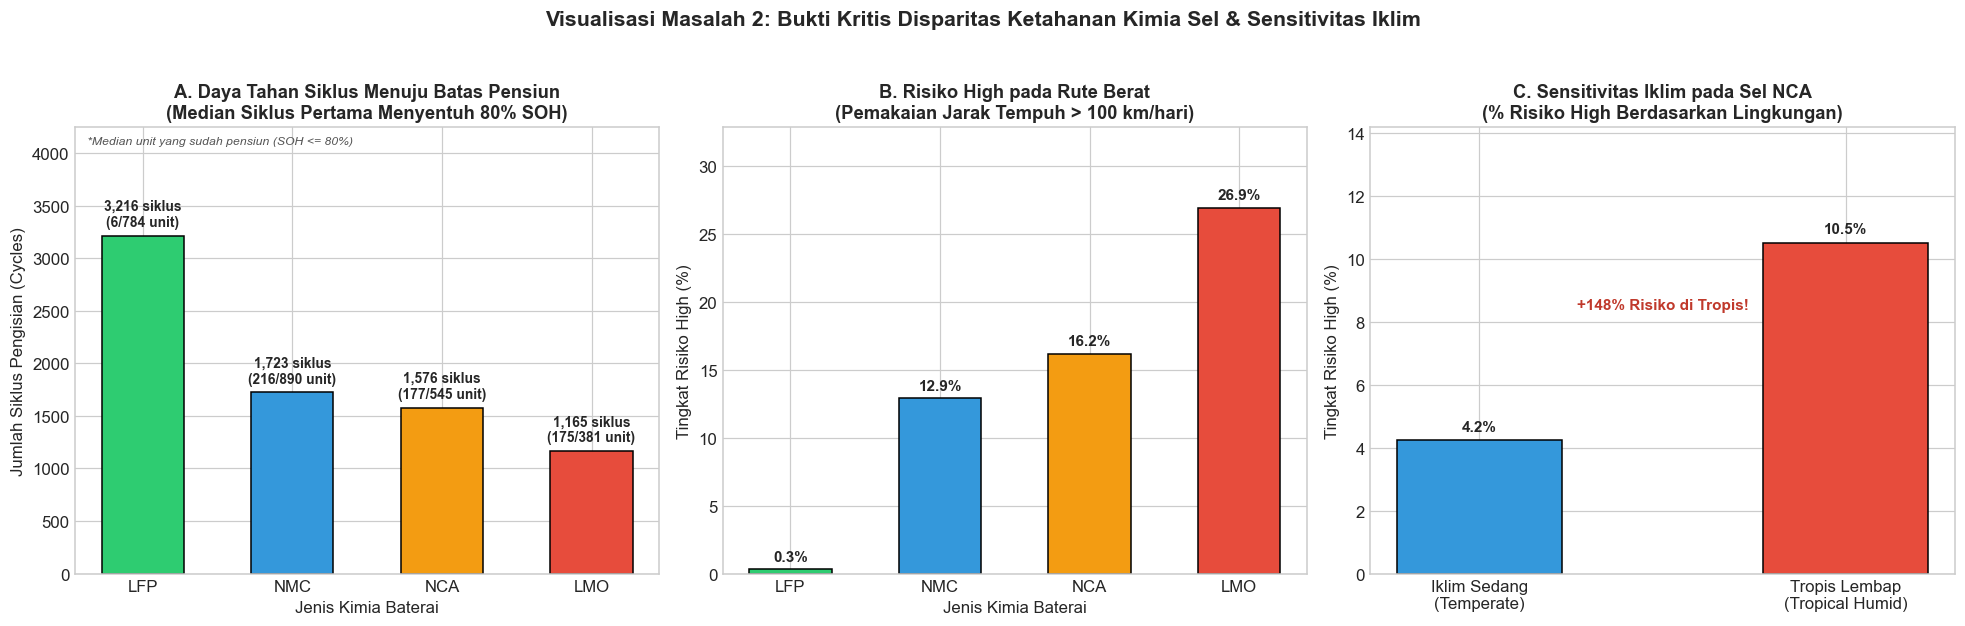

In [9]:
# Visualisasi Masalah 2: Disparitas Kimia Sel & Sensitivitas Iklim
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

chem_order = ['LFP', 'NMC', 'NCA', 'LMO']
chem_palette = {'LFP': '#2ecc71', 'NMC': '#3498db', 'NCA': '#f39c12', 'LMO': '#e74c3c'}

# Subplot 2A: Median Siklus Saat Pertama Menyentuh 80% SOH
cycles_to_retire = retire_med.reindex(chem_order).values
bars2a = axes[0].bar(
    chem_order, cycles_to_retire,
    color=[chem_palette[c] for c in chem_order],
    edgecolor='black', width=0.55
)
axes[0].set_title('A. Daya Tahan Siklus Menuju Batas Pensiun\n(Median Siklus Pertama Menyentuh 80% SOH)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jenis Kimia Baterai', fontsize=11)
axes[0].set_ylabel('Jumlah Siklus Pengisian (Cycles)', fontsize=11)
axes[0].set_ylim(0, max(cycles_to_retire) * 1.32)
for chemistry, bar in zip(chem_order, bars2a):
    yval = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + max(cycles_to_retire) * 0.02,
        f"{yval:,.0f} siklus\n({retire_n[chemistry]}/{chem_n[chemistry]} unit)",
        ha='center', va='bottom', fontweight='bold', fontsize=9
    )
axes[0].text(
    0.02, 0.98,
    '*Median unit yang sudah pensiun (SOH <= 80%)',
    transform=axes[0].transAxes, ha='left', va='top',
    fontsize=8, style='italic', color='#555555'
)

# Subplot 2B: Tingkat Risiko High Saat Pemakaian > 100 km/hari
heavy_fail_rates = heavy_rate.reindex(chem_order).values
bars2b = axes[1].bar(
    chem_order, heavy_fail_rates,
    color=[chem_palette[c] for c in chem_order],
    edgecolor='black', width=0.55
)
axes[1].set_title('B. Risiko High pada Rute Berat\n(Pemakaian Jarak Tempuh > 100 km/hari)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jenis Kimia Baterai', fontsize=11)
axes[1].set_ylabel('Tingkat Risiko High (%)', fontsize=11)
axes[1].set_ylim(0, max(heavy_fail_rates) * 1.22)
for bar, value in zip(bars2b, heavy_fail_rates):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        value + max(heavy_fail_rates) * 0.015,
        f"{value:.1f}%",
        ha='center', va='bottom', fontweight='bold', fontsize=10
    )

# Subplot 2C: Perbandingan Iklim pada Baterai NCA (Tropis Lembap vs Sedang)
nca_climate = pd.Series({
    'Iklim Sedang\n(Temperate)': nca_clim['temperate'],
    'Tropis Lembap\n(Tropical Humid)': nca_clim['tropical_humid']
})
bars2c = axes[2].bar(
    nca_climate.index, nca_climate.values,
    color=['#3498db', '#e74c3c'],
    edgecolor='black', width=0.45
)
axes[2].set_title('C. Sensitivitas Iklim pada Sel NCA\n(% Risiko High Berdasarkan Lingkungan)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Tingkat Risiko High (%)', fontsize=11)
axes[2].set_ylim(0, nca_climate.max() * 1.35)
for bar in bars2c:
    yval = bar.get_height()
    axes[2].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + nca_climate.max() * 0.02,
        f"{yval:.1f}%",
        ha='center', va='bottom', fontweight='bold', fontsize=10
    )
axes[2].text(
    0.5, nca_climate.max() * 0.80,
    f"+{nca_delta:.0f}% Risiko di Tropis!",
    ha='center', color='#c0392b', fontweight='bold', fontsize=10
)

plt.suptitle('Visualisasi Masalah 2: Bukti Kritis Disparitas Ketahanan Kimia Sel & Sensitivitas Iklim', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Visualisasi Masalah 3: Pola Pemakaian Berat Mempercepat Kerusakan Tanpa Disadari

> **🎯 Untuk Siapa**: *Fleet Manager*, Operator Stasiun Pengisian (SPKLU/CPO), dan Pengembang Software BMS aplikasi pengemudi.
>
> **❗ Masalah**: Pengguna dan operator armada tidak menyadari bahwa jarak tempuh tinggi, *fast charging* sering, dan pengosongan baterai dalam memiliki efek akumulatif yang besar terhadap percepatan degradasi.
>
> **✅ Solusi**: Terapkan rotasi kendaraan dari rute berat ke rute ringan, batasi frekuensi fast charge dan kedalaman pengosongan (*depth of discharge*) melalui konfigurasi BMS, serta sediakan paket *smart charging* bersama operator SPKLU.
>
> **📊 Bukti Visual (dihitung dari dataset)**:
> - **Subplot A**: risiko High naik dari **3,1%** pada pemakaian <30 km/hari menjadi **12,1%** pada >100 km/hari (sekitar **3,9 kali lipat**).
> - **Subplot B**: risiko High meningkat seiring jumlah faktor beban serentak — dari **4,5%** (0 faktor) menjadi **6,3%** (1 faktor), **9,2%** (2 faktor), dan **13,3%** (3 faktor: jarak jauh + fast charge >50% + DoD >70%).
> - **Subplot C**: pada kelompok siklus yang sama, baterai dengan fast charge tinggi memiliki rata-rata SOH yang lebih rendah dibanding fast charge rendah—menunjukkan penalti kumulatif fast charging.


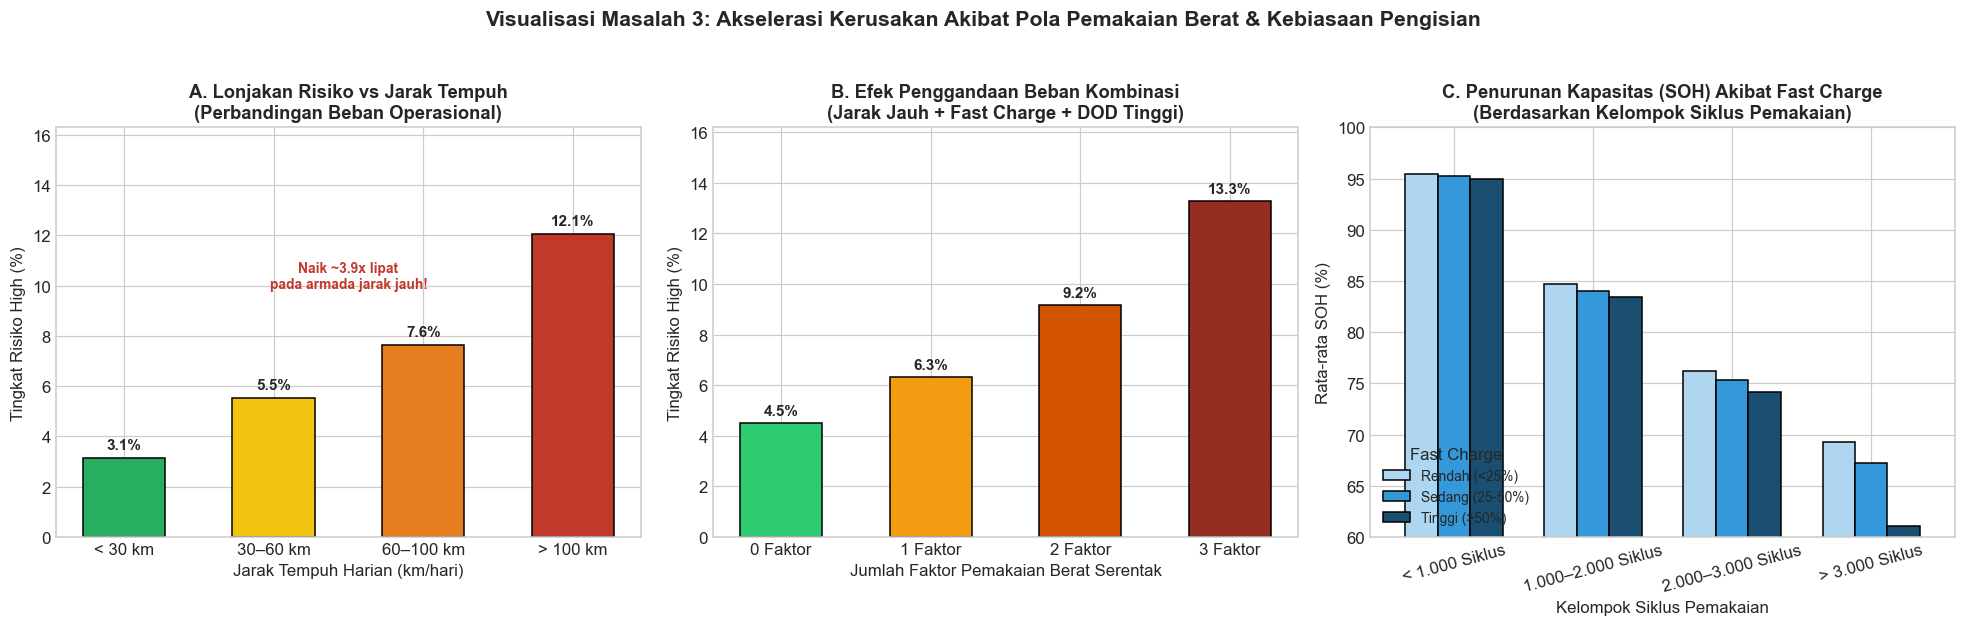

In [10]:
# Visualisasi Masalah 3: Akselerasi Kerusakan Akibat Pola Pemakaian Berat
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot 3A: Tingkat Risiko High vs Jarak Tempuh Harian
dist_rates = dist_rate.values
dist_names = ['< 30 km', '30–60 km', '60–100 km', '> 100 km']
bars3a = axes[0].bar(
    dist_names, dist_rates,
    color=['#27ae60', '#f1c40f', '#e67e22', '#c0392b'],
    edgecolor='black', width=0.55
)
axes[0].set_title('A. Lonjakan Risiko vs Jarak Tempuh\n(Perbandingan Beban Operasional)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Jarak Tempuh Harian (km/hari)', fontsize=11)
axes[0].set_ylabel('Tingkat Risiko High (%)', fontsize=11)
axes[0].set_ylim(0, max(dist_rates) * 1.35)
for bar, value in zip(bars3a, dist_rates):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        value + max(dist_rates) * 0.02,
        f"{value:.1f}%",
        ha='center', va='bottom', fontweight='bold', fontsize=10
    )
distance_ratio = dist_rate.iloc[-1] / dist_rate.iloc[0]
axes[0].text(
    1.5, max(dist_rates) * 0.82,
    f"Naik ~{distance_ratio:.1f}x lipat\npada armada jarak jauh!",
    ha='center', color='#c0392b', fontweight='bold', fontsize=9
)

# Subplot 3B: Efek Penggandaan Kombinasi Faktor Beban Berat
combo_values = combo_rate.reindex([0, 1, 2, 3]).values
bars3b = axes[1].bar(
    ['0 Faktor', '1 Faktor', '2 Faktor', '3 Faktor'], combo_values,
    color=['#2ecc71', '#f39c12', '#d35400', '#962d22'],
    edgecolor='black', width=0.55
)
axes[1].set_title('B. Efek Penggandaan Beban Kombinasi\n(Jarak Jauh + Fast Charge + DOD Tinggi)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Jumlah Faktor Pemakaian Berat Serentak', fontsize=11)
axes[1].set_ylabel('Tingkat Risiko High (%)', fontsize=11)
axes[1].set_ylim(0, max(combo_values) * 1.22)
for bar, value in zip(bars3b, combo_values):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        value + max(combo_values) * 0.015,
        f"{value:.1f}%",
        ha='center', va='bottom', fontweight='bold', fontsize=10
    )

# Subplot 3C: Penalti Fast Charge terhadap SOH Berdasarkan Siklus
fc_cycle = (
    df.groupby(['cycle_bracket', 'fast_charge_level'], observed=False)['state_of_health_pct']
      .mean()
      .unstack()
)
fc_cycle.plot(kind='bar', ax=axes[2], color=['#aed6f1', '#3498db', '#1b4f72'], edgecolor='black', width=0.7)
axes[2].set_title('C. Penurunan Kapasitas (SOH) Akibat Fast Charge\n(Berdasarkan Kelompok Siklus Pemakaian)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Kelompok Siklus Pemakaian', fontsize=11)
axes[2].set_ylabel('Rata-rata SOH (%)', fontsize=11)
axes[2].set_ylim(60, 100)
axes[2].legend(title='Fast Charge', loc='lower left', fontsize=9)
axes[2].tick_params(axis='x', rotation=15)

plt.suptitle('Visualisasi Masalah 3: Akselerasi Kerusakan Akibat Pola Pemakaian Berat & Kebiasaan Pengisian', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


---
## Modul 6: Penentuan Informasi Strategis

Bagian ini merangkum intisari temuan analitik menjadi **3 Masalah Strategis**, dampak nyata, solusi konkret, dan pihak pengguna yang berkepentingan. Seluruh angka di bawah dihitung dari dataset dan konsisten dengan visualisasi pada Modul 5.

---

### 📌 Masalah 1: Baterai rusak diam-diam, peringatannya terlambat

- **Untuk Siapa**: Tim Operasional Armada (taksi online, logistik, rental), Teknisi Perawatan (*Maintenance*), dan Produsen EV.
- **Masalah & Fakta Data**:
  - Kerusakan baterai baru terlihat jelas setelah hampir pensiun.
  - Baterai berlabel **“Medium”** memiliki **median sisa sekitar 53 siklus** (sekitar 1–2 bulan pemakaian); rata-rata 202 siklus karena distribusinya ekor panjang.
  - Baterai berlabel **“High”** memiliki **median 0 sisa siklus** (rata-rata 9 siklus).
  - Secara keseluruhan, **22% baterai di data pernah menyentuh batas pensiun**, dan pada pengecekan terakhir **18,5% sudah berstatus High dan 17,6% Medium**.
- **Dampak Nyata**:
  - Kendaraan bisa mendadak turun performa atau tidak layak pakai tanpa persiapan.
  - Servis dan penggantian baterai menjadi tindakan darurat, bukan terjadwal secara terencana.
- **Solusi Aksi**:
  - **Pantau hambatan dalam (internal resistance) sebagai alarm dini**.
  - Di data, tingkat risiko High:
    - **0,04%** di bawah $60\text{ m}\Omega$
    - **0,34%** di rentang $60–70\text{ m}\Omega$
    - **5,42%** di rentang $70–80\text{ m}\Omega$
    - **28,71%** di rentang $80–90\text{ m}\Omega$
    - **83,20%** di atas $90\text{ m}\Omega$
  - **Jadwalkan pemeriksaan saat angka masuk $60–70\text{ m}\Omega$**, jangan menunggu label risiko berubah. Risiko masih rendah pada rentang ini, tetapi sudah mulai naik dan memberi jendela waktu pencegahan.

---

### 📌 Masalah 2: Salah memilih jenis baterai untuk pemakaian tertentu

- **Untuk Siapa**: Produsen baterai dan kendaraan (R&D, pemilihan chemistry), Operator Armada (pengadaan kendaraan), serta Perusahaan Leasing dan Asuransi (penentuan premi dan proyeksi nilai sisa aset).
- **Masalah & Fakta Data**:
  - Jenis baterai sering dipilih tanpa mempertimbangkan cara pakai dan iklim operasional, padahal perbedaan antar jenis sangat besar:

| Jenis Baterai | Median Siklus Pertama Menyentuh 80% SOH | Unit yang Sudah Pensiun | Risiko High saat Dipakai >100 km/hari |
| :--- | :--- | :--- | :--- |
| **LFP** | ~3.216 siklus | 6 dari 784 unit | **0,3%** |
| **NMC** | ~1.723 siklus | 216 dari 890 unit | **12,9%** |
| **NCA** | ~1.576 siklus | 177 dari 545 unit | **16,2%** |
| **LMO** | ~1.165 siklus | 175 dari 381 unit | **26,9%** |

  - **Pengaruh Iklim**: Baterai jenis **NCA di iklim tropis lembap mencapai 10,5% risiko High**, dibanding hanya **4,2% di iklim sedang** (**+148%**).
  - **Catatan LFP**: Karena baru 6 dari 784 unit LFP yang menyentuh 80% SOH, angka ~3.163 siklus adalah median unit yang sudah pensiun dan belum tentu mewakili seluruh populasi LFP.
- **Dampak Nyata**:
  - Baterai yang salah pilih habis lebih cepat dari rencana investasi awal.
  - Biaya penggantian dan *downtime* kendaraan naik, terutama pada operasional armada berat.
  - Garansi dan perkiraan nilai sisa (*residual value*) kendaraan menjadi meleset.
  *(Catatan: data tidak memuat biaya, jadi dampak finansial di atas adalah penalaran dari pola, bukan angka rupiah riil).*
- **Solusi Aksi**:
  - **Armada berat atau iklim ekstrem**: Wajibkan memilih jenis **LFP**.
  - **Pemakaian ringan**: Penggunaan **NMC atau NCA** masih wajar dan ekonomis.
  - **Hindari LMO** untuk pemakaian intensif armada komersial.
  - **Batasi fast charge pada NCA** (paling sensitif terhadap penalti laju penurunan kapasitas) dan **hindari pengosongan dalam pada LMO**.

---

### 📌 Masalah 3: Pola pemakaian berat mempercepat kerusakan tanpa disadari

- **Untuk Siapa**: Operator armada kendaraan listrik (*Fleet Manager*), Operator Stasiun Pengisian Kendaraan Listrik (SPKLU/CPO), dan Pengembang BMS (*Battery Management System*) serta aplikasi pengemudi.
- **Masalah & Fakta Data**:
  - Pengguna dan operator armada tidak menyadari bahwa intensitas pemakaian memiliki efek akumulatif yang besar.
  - Di data, tingkat risiko High melonjak dari **3,1% (di bawah 30 km/hari)** menjadi **12,1% (di atas 100 km/hari)**—sekitar **3,9 kali lipat**.
  - Kombinasi pemakaian rute jauh, *fast charge* frekuensi tinggi, dan pengosongan dalam (*high depth of discharge*) meningkatkan risiko High dari **4,5% (0 faktor)** menjadi **13,3% (3 faktor)**.
- **Dampak Nyata**:
  - Armada dengan rute berat menuai baterai pensiun jauh lebih awal dari estimasi masa pakai.
  - Biaya per kilometer naik karena baterai harus diganti lebih cepat.
  - Operator stasiun pengisian daya (CPO) saat ini tidak memiliki insentif untuk mengurangi pengisian daya yang merusak sel baterai.
- **Solusi Aksi**:
  - **Rotasi kendaraan**: Terapkan manajemen rotasi kendaraan secara berkala dari rute berat ke rute ringan.
  - **Proteksi otomatis via BMS**: Batasi frekuensi *fast charge* harian dan kedalaman pengosongan (*depth of discharge*) secara otomatis melalui konfigurasi Battery Management System (BMS).
  - **Paket Smart Charging**: Tawarkan paket *smart charging* terkelola atau tarif daya adaptif di stasiun pengisian yang memperpanjang umur baterai.

---

### 🧾 Ringkasan Keputusan: Untuk Siapa, Masalah, Solusi, dan Bukti

| Masalah | Untuk Siapa | Solusi | Bukti Kunci dari Dataset |
| :--- | :--- | :--- | :--- |
| **1. Baterai rusak diam-diam, peringatan terlambat** | Tim Operasional Armada, Teknisi Perawatan, Produsen EV | Alarm dini hambatan dalam 60–70 mΩ; servis terjadwal sebelum label Medium/High | Median RUL Medium ~53 siklus; risiko High naik dari 0,34% (60–70 mΩ) ke 83,20% (>90 mΩ) |
| **2. Salah memilih kimia sel** | Tim Pengadaan, Pabrikan EV, Leasing & Asuransi | LFP untuk armada berat/tropis; NMC/NCA untuk pemakaian ringan; hindari LMO untuk armada intensif | Risiko High >100 km/hari: LFP 0,3% vs LMO 26,9%; NCA tropis 10,5% vs sedang 4,2% |
| **3. Pola pemakaian berat** | Fleet Manager, Operator SPKLU/CPO, Pengembang BMS | Rotasi unit, batasi fast charge & DoD via BMS, terapkan smart charging | Risiko High naik dari 3,1% (<30 km/hari) ke 12,1% (>100 km/hari); 4,5% (0 faktor) ke 13,3% (3 faktor) |

> **Batasan:** Dataset ini sintetis dan tidak memuat variabel biaya riil. Seluruh rekomendasi adalah inferensi dari pola telemetri untuk tujuan edukasi dan perancangan metodologi, bukan keputusan operasional, finansial, atau keselamatan yang mengikat.


In [11]:
# Tabel keputusan strategis (versi dinamis, sumber angka sama dengan visualisasi)
ringkasan_strategis = pd.DataFrame([
    {
        'Masalah': '1. Baterai rusak diam-diam, peringatan terlambat',
        'Untuk Siapa': 'Tim Operasional Armada, Teknisi Perawatan, Produsen EV',
        'Masalah Inti': 'Label risiko konvensional baru berubah saat baterai hampir pensiun',
        'Solusi': 'Alarm dini hambatan dalam 60–70 mΩ dan servis terjadwal',
        'Bukti Kunci': f"Median RUL Medium {rul_med['Medium']:.0f} siklus; risiko High {res_rate.iloc[1]:.2f}% (60–70 mΩ) -> {res_rate.iloc[-1]:.2f}% (>90 mΩ)",
    },
    {
        'Masalah': '2. Salah memilih kimia sel untuk pemakaian & iklim',
        'Untuk Siapa': 'Tim Pengadaan, Pabrikan EV, Leasing & Asuransi',
        'Masalah Inti': 'Kimia sel tidak disesuaikan dengan beban rute dan iklim operasional',
        'Solusi': 'LFP untuk armada berat/tropis; NMC/NCA untuk pemakaian ringan; hindari LMO untuk armada intensif',
        'Bukti Kunci': f"Risiko High >100 km/hari: LFP {heavy_rate['LFP']:.1f}% vs LMO {heavy_rate['LMO']:.1f}%; NCA tropis {nca_clim['tropical_humid']:.1f}% vs sedang {nca_clim['temperate']:.1f}%",
    },
    {
        'Masalah': '3. Pola pemakaian berat mempercepat kerusakan',
        'Untuk Siapa': 'Fleet Manager, Operator SPKLU/CPO, Pengembang BMS',
        'Masalah Inti': 'Efek akumulatif jarak jauh, fast charge sering, dan pengosongan dalam',
        'Solusi': 'Rotasi unit, batasi fast charge & DoD via BMS, terapkan smart charging',
        'Bukti Kunci': f"Risiko High {dist_rate.iloc[0]:.1f}% (<30 km/hari) -> {dist_rate.iloc[-1]:.1f}% (>100 km/hari); {combo_rate.loc[0]:.1f}% (0 faktor) -> {combo_rate.loc[3]:.1f}% (3 faktor)",
    },
])
ringkasan_strategis

,Masalah,Untuk Siapa,Masalah Inti,Solusi,Bukti Kunci
0,"1. Baterai rusak diam-diam, peringatan terlambat","Tim Operasional Armada, Teknisi Perawatan, Produsen EV",Label risiko konvensional baru berubah saat baterai hampir pensiun,Alarm dini hambatan dalam 60–70 mΩ dan servis terjadwal,Median RUL Medium 53 siklus; risiko High 0.34% (60–70 mΩ) -> 83.20% (>90 mΩ)
1,2. Salah memilih kimia sel untuk pemakaian & iklim,"Tim Pengadaan, Pabrikan EV, Leasing & Asuransi",Kimia sel tidak disesuaikan dengan beban rute dan iklim operasional,LFP untuk armada berat/tropis; NMC/NCA untuk pemakaian ringan; hindari LMO untuk armada intensif,Risiko High >100 km/hari: LFP 0.3% vs LMO 26.9%; NCA tropis 10.5% vs sedang 4.2%
2,3. Pola pemakaian berat mempercepat kerusakan,"Fleet Manager, Operator SPKLU/CPO, Pengembang BMS","Efek akumulatif jarak jauh, fast charge sering, dan pengosongan dalam","Rotasi unit, batasi fast charge & DoD via BMS, terapkan smart charging",Risiko High 3.1% (<30 km/hari) -> 12.1% (>100 km/hari); 4.5% (0 faktor) -> 13.3% (3 faktor)
